# Dataset comparison at E7.5

Use only **SHH, SOX2, HOXA1, and PMP22**. PMP22 replaces the unavailable NKX2-1: it was randomly selected (seed 42) from eight genes mentioned in the [original paper](https://doi.org/10.1016/j.cell.2025.05.035) and present in both original E7.5 embryos: Apoc2, Pmp22, Cer1, Otx2, Sfrp1, Apela, Msx1, Id2.

Pool cells from the two original E7.5 embryos and calculate Pearson correlations across cells. Compare with TOME E7.5 using the **mean absolute difference over the six unique gene pairs**. Lower is better; zero means identical correlations. TOME is the only candidate here.

Use the original files' stored expression (`X`) and TOME's Seurat log-normalized expression (`logcounts` after conversion). No normalization using unobserved genes is performed here.

Requires the Python packages in `dataset/requirements.txt`, plus R with `Seurat`, `SingleCellExperiment`, and `zellkonverter` for the TOME RDS file. Run from the repository root or this notebook's directory.

Reads the original E7.5 embryos from `dataset/data/GSE278603_RAW/` and uses `load_dataset("tome", timepoint="E7.5", output="anndata")` for TOME. The loader reuses the cached RDS file or downloads it if missing, then converts it to AnnData using Homebrew R (`/opt/homebrew/bin/Rscript`).

TOME uses Ensembl IDs rather than gene symbols. The panel is matched using the mouse IDs for [Shh](https://www.ncbi.nlm.nih.gov/gene/20423), [Sox2](https://www.ensembl.org/id/ENSMUSG00000074637), [Hoxa1](https://www.ensembl.org/id/ENSMUSG00000029844), and [Pmp22](https://www.ensembl.org/id/ENSMUSG00000018217).

In [1]:
from pathlib import Path
from itertools import combinations
import os
import sys

import anndata as ad
import numpy as np
import pandas as pd

root = Path.cwd()
if not (root / "dataset").is_dir():
    root = root.parent
sys.path.insert(0, str(root / "dataset"))
from load_dataset import DATA_DIR, load_dataset

os.environ["PATH"] = "/opt/homebrew/bin" + os.pathsep + os.environ["PATH"]

genes = ["SHH", "SOX2", "HOXA1", "PMP22"]
stage = "E7.5"

In [2]:
def panel_expression(adata, layer=None):
    names = pd.Series(adata.var_names, index=adata.var_names.str.upper())
    expression = adata[:, names.loc[genes].tolist()].to_df(layer=layer)
    expression.columns = genes
    return expression

original_files = sorted((DATA_DIR / "GSE278603_RAW").glob(f"*_{stage}_*.h5ad"))
original_expression = pd.concat(
    [panel_expression(ad.read_h5ad(path)) for path in original_files],
    ignore_index=True,
)
original_correlation = original_expression.corr()
original_correlation

,SHH,SOX2,HOXA1,PMP22
SHH,1.000000,0.001854,-0.004413,-0.006075
SOX2,0.001854,1.000000,-0.006215,-0.027755
HOXA1,-0.004413,-0.006215,1.000000,-0.002742
PMP22,-0.006075,-0.027755,-0.002742,1.000000


In [3]:
tome = load_dataset("tome", timepoint=stage, output="anndata")[f"seurat_object_{stage}"]
tome_gene_ids = {
    "SHH": "ENSMUSG00000002633",
    "SOX2": "ENSMUSG00000074637",
    "HOXA1": "ENSMUSG00000029844",
    "PMP22": "ENSMUSG00000018217",
}
tome_expression = tome[:, [tome_gene_ids[gene] for gene in genes]].to_df(layer="logcounts")
tome_expression.columns = genes
tome_correlation = tome_expression.corr()
tome_correlation

Loading required package: Seurat
Loading required package: SeuratObject
Loading required package: sp

Attaching package: ‘SeuratObject’

The following objects are masked from ‘package:base’:

    intersect, t

v5.6 adds significant improvements in speed and efficiency, particularly for large datasets.
For more information, see https://satijalab.org/seurat/articles/announcements.

Registered S3 method overwritten by 'zellkonverter':
  method                                             from      
  py_to_r.pandas.core.arrays.categorical.Categorical reticulate
ℹ Using the 'counts' assay as the X matrix


,SHH,SOX2,HOXA1,PMP22
SHH,1.000000,-0.020462,-0.007343,-0.007610
SOX2,-0.020462,1.000000,-0.012935,-0.105406
HOXA1,-0.007343,-0.012935,1.000000,0.056195
PMP22,-0.007610,-0.105406,0.056195,1.000000


In [4]:
pairs = list(combinations(genes, 2))
comparison = pd.DataFrame({
    "gene_pair": [f"{a} / {b}" for a, b in pairs],
    "original": [original_correlation.loc[a, b] for a, b in pairs],
    "TOME E7.5": [tome_correlation.loc[a, b] for a, b in pairs],
}).set_index("gene_pair")
comparison["absolute_difference"] = (comparison["TOME E7.5"] - comparison["original"]).abs()
comparison

,original,TOME E7.5,absolute_difference
gene_pair,,,
SHH / SOX2,0.001854,-0.020462,0.022316
SHH / HOXA1,-0.004413,-0.007343,0.002929
SHH / PMP22,-0.006075,-0.007610,0.001535
SOX2 / HOXA1,-0.006215,-0.012935,0.006720
SOX2 / PMP22,-0.027755,-0.105406,0.077651
HOXA1 / PMP22,-0.002742,0.056195,0.058937


In [5]:
scores = pd.DataFrame({
    "dataset": ["TOME E7.5"],
    "score": [np.mean(comparison["absolute_difference"].to_numpy())],
}).sort_values("score").reset_index(drop=True)
scores

,dataset,score
0,TOME E7.5,0.028348


## TOME correlation matrix and factor loadings

Save the four-gene Pearson correlation matrix and fit scikit-learn factor analysis with `d = 256` to the **full TOME E7.5 gene set**, using its `logcounts` layer and a random sample of **1,000 cells without replacement (seed 42)**. The four-gene correlation matrix continues to use all TOME E7.5 cells. FactorAnalysis centers each gene; no additional variance scaling is applied. The loading matrix has all TOME Ensembl gene IDs as rows and factors as columns. CSV outputs are written to `preprocessing/results/`.

In [6]:
output_dir = root / "preprocessing" / "results"
output_dir.mkdir(parents=True, exist_ok=True)
tome_correlation.to_csv(output_dir / f"tome_{stage}_gene_correlation.csv", index_label="gene")
tome_correlation

,SHH,SOX2,HOXA1,PMP22
SHH,1.000000,-0.020462,-0.007343,-0.007610
SOX2,-0.020462,1.000000,-0.012935,-0.105406
HOXA1,-0.007343,-0.012935,1.000000,0.056195
PMP22,-0.007610,-0.105406,0.056195,1.000000


In [8]:
from sklearn.decomposition import FactorAnalysis

d = 256
cell_indices = np.random.default_rng(42).choice(tome.n_obs, size=1000, replace=False)
tome_sample = tome[cell_indices, :]
factor_analysis = FactorAnalysis(n_components=d, copy=False)
factor_analysis.fit(tome_sample.to_df(layer="logcounts"))
gene_loadings = pd.DataFrame(
    factor_analysis.components_.T,
    index=pd.Index(tome.var_names, name="gene_id"),
    columns=[f"factor_{i + 1}" for i in range(d)],
)
gene_loadings.to_csv(output_dir / f"tome_{stage}_full_gene_factor_loadings_d{d}.csv")
gene_loadings

,factor_1,factor_2,factor_3,factor_4,factor_5,factor_6,factor_7,factor_8,factor_9,factor_10,...,factor_247,factor_248,factor_249,factor_250,factor_251,factor_252,factor_253,factor_254,factor_255,factor_256
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSMUSG00000051951,-3.190007e-05,2.057159e-03,5.808128e-04,9.558631e-05,4.987182e-04,2.212908e-03,1.402672e-04,-2.380127e-05,-3.877288e-05,-1.294135e-04,...,1.994687e-12,-6.215397e-12,1.412298e-15,-5.331691e-13,-4.098454e-12,1.707244e-12,4.754330e-12,6.401229e-13,-4.460984e-12,9.848851e-13
ENSMUSG00000089699,-1.198048e-21,2.299000e-18,-2.018839e-15,-9.211716e-17,4.757874e-16,4.831553e-16,8.282834e-17,1.527063e-16,-2.898200e-16,-3.046084e-16,...,-1.708711e-22,-1.567511e-22,-6.169876e-23,7.976645e-24,-2.447035e-23,1.218148e-23,-3.061658e-23,3.296169e-23,-1.823215e-24,-4.324896e-25
ENSMUSG00000102343,1.539242e-23,1.333328e-19,2.699963e-17,-1.763474e-16,2.461170e-16,-6.726327e-17,7.404640e-17,-7.187242e-17,-6.971194e-17,-6.573153e-17,...,1.229587e-22,-1.129648e-22,-7.992679e-24,6.469454e-23,-2.437903e-22,1.406703e-22,3.868881e-24,-3.017066e-22,-7.452008e-23,-1.875688e-22
ENSMUSG00000025900,3.039660e-24,6.384379e-20,2.218571e-18,-4.135460e-17,7.393822e-17,-1.203916e-16,6.445338e-17,-3.166250e-17,-1.254508e-16,4.110280e-17,...,5.005923e-22,1.237067e-22,6.897085e-22,-1.951317e-22,3.362670e-22,5.840639e-23,-1.298956e-23,3.082356e-22,-2.845545e-23,-2.529471e-22
ENSMUSG00000025902,-3.243085e-02,-8.618543e-02,2.302337e-02,8.552936e-02,-4.174502e-02,-2.455945e-02,-8.028313e-02,3.023963e-01,2.309605e-01,-6.156568e-02,...,-2.428088e-02,-9.243038e-02,7.769923e-02,9.122436e-02,4.912796e-02,4.697389e-03,5.279528e-02,-7.038318e-02,-3.710744e-02,1.042131e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSMUSG00000079808,-6.325465e-05,-1.669857e-04,3.629317e-05,-1.141907e-04,-7.257135e-05,-4.610840e-05,-1.182111e-04,-6.365608e-05,-8.448776e-05,-8.673477e-05,...,5.780762e-04,1.067092e-03,1.015361e-03,1.139024e-03,8.307447e-04,-5.857822e-04,-1.548735e-03,-2.474640e-03,2.688730e-03,3.970635e-03
ENSMUSG00000095041,2.508602e-02,3.924236e-03,2.749336e-02,-9.513332e-04,-1.563927e-02,-9.135814e-03,1.942692e-03,-1.009072e-02,9.010760e-02,3.574209e-03,...,2.822849e-02,-5.025369e-03,-2.093449e-02,-2.498992e-02,1.389329e-02,1.872474e-02,1.670945e-02,1.829458e-02,1.127184e-02,-6.127429e-03
ENSMUSG00000063897,1.584589e-02,-2.345955e-02,4.435707e-03,2.339080e-02,-1.294470e-02,6.704331e-03,4.935463e-02,2.228050e-04,9.761993e-03,2.938123e-02,...,-1.961567e-03,-3.811835e-02,2.694795e-02,9.599124e-03,-1.355912e-02,6.707810e-03,1.730390e-02,-4.250123e-02,-2.880285e-02,-1.500332e-02


## Four-gene correlation clustermap

Plot the saved four-gene Pearson correlation matrix computed from all TOME E7.5 cells. Cluster genes by average linkage using distance `1 - correlation`, with the same order on both axes. Save the figure alongside the correlation CSV.

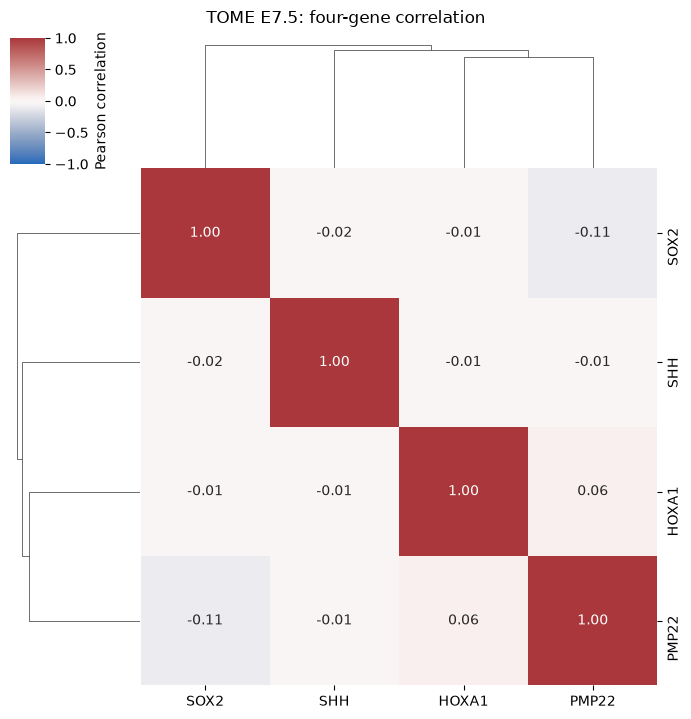

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

panel_linkage = linkage(
    squareform(np.clip(1 - tome_correlation.to_numpy(), 0, 2), checks=False),
    method="average",
)
panel_clustermap = sns.clustermap(
    tome_correlation,
    row_linkage=panel_linkage,
    col_linkage=panel_linkage,
    cmap="vlag", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", figsize=(7, 7),
    cbar_kws={"label": "Pearson correlation"},
)
panel_clustermap.fig.suptitle(f"TOME {stage}: four-gene correlation", y=1.02)
panel_clustermap.savefig(output_dir / f"tome_{stage}_panel_correlation_clustermap.png", dpi=150)
plt.show()

## Full-gene correlation matrix and clustermap

Compute Pearson correlations across the same 1,000 sampled cells used for factor analysis, using all TOME genes and the `logcounts` layer. Save the complete matrix as a compressed NumPy archive with `correlation` and `gene_ids` arrays in matching order. Correlations involving zero-variance genes are undefined (`NaN`); these genes are excluded only from the clustermap. Clustering uses average linkage on `1 - correlation`.

The full matrix has 29,452 × 29,452 entries (about 3.5 GB in float32 before compression). Clustering and plotting require additional memory and can take substantial time.

In [10]:
full_expression = tome_sample.to_df(layer="logcounts")
full_gene_correlation = pd.DataFrame(
    np.corrcoef(full_expression.to_numpy(), rowvar=False, dtype=np.float32),
    index=pd.Index(full_expression.columns, name="gene_id"),
    columns=full_expression.columns,
)
np.savez_compressed(
    output_dir / f"tome_{stage}_full_gene_correlation_1000cells.npz",
    correlation=full_gene_correlation.to_numpy(),
    gene_ids=full_gene_correlation.index.to_numpy(dtype=str),
)
full_gene_correlation

/opt/anaconda3/envs/hackathon/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/anaconda3/envs/hackathon/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,ENSMUSG00000051951,ENSMUSG00000089699,ENSMUSG00000102343,ENSMUSG00000025900,ENSMUSG00000025902,ENSMUSG00000104328,ENSMUSG00000033845,ENSMUSG00000025903,ENSMUSG00000104217,ENSMUSG00000033813,...,ENSMUSG00000079192,ENSMUSG00000079794,ENSMUSG00000094799,ENSMUSG00000095019,ENSMUSG00000094915,ENSMUSG00000079808,ENSMUSG00000095041,ENSMUSG00000063897,ENSMUSG00000096730,ENSMUSG00000095742
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSMUSG00000051951,1.000000,NaN,NaN,NaN,-0.010974,NaN,0.043559,0.055178,-0.001001,0.037294,...,NaN,NaN,NaN,NaN,NaN,-0.001416,-0.013094,-0.019642,NaN,-0.002005
ENSMUSG00000089699,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENSMUSG00000102343,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENSMUSG00000025900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENSMUSG00000025902,-0.010974,NaN,NaN,NaN,1.000000,NaN,0.085837,0.235937,0.021114,-0.068947,...,NaN,NaN,NaN,NaN,NaN,0.029875,0.145747,0.075304,NaN,-0.011269
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSMUSG00000079808,-0.001416,NaN,NaN,NaN,0.029875,NaN,-0.022536,-0.009913,-0.001416,-0.028765,...,NaN,NaN,NaN,NaN,NaN,1.000000,0.026225,-0.027793,NaN,-0.002837
ENSMUSG00000095041,-0.013094,NaN,NaN,NaN,0.145747,NaN,0.167102,0.187363,-0.013094,0.097487,...,NaN,NaN,NaN,NaN,NaN,0.026225,1.000000,0.146042,NaN,0.005448
ENSMUSG00000063897,-0.019642,NaN,NaN,NaN,0.075304,NaN,0.188064,0.094016,-0.019643,0.048387,...,NaN,NaN,NaN,NaN,NaN,-0.027793,0.146042,1.000000,NaN,0.019790


RecursionError: maximum recursion depth exceeded

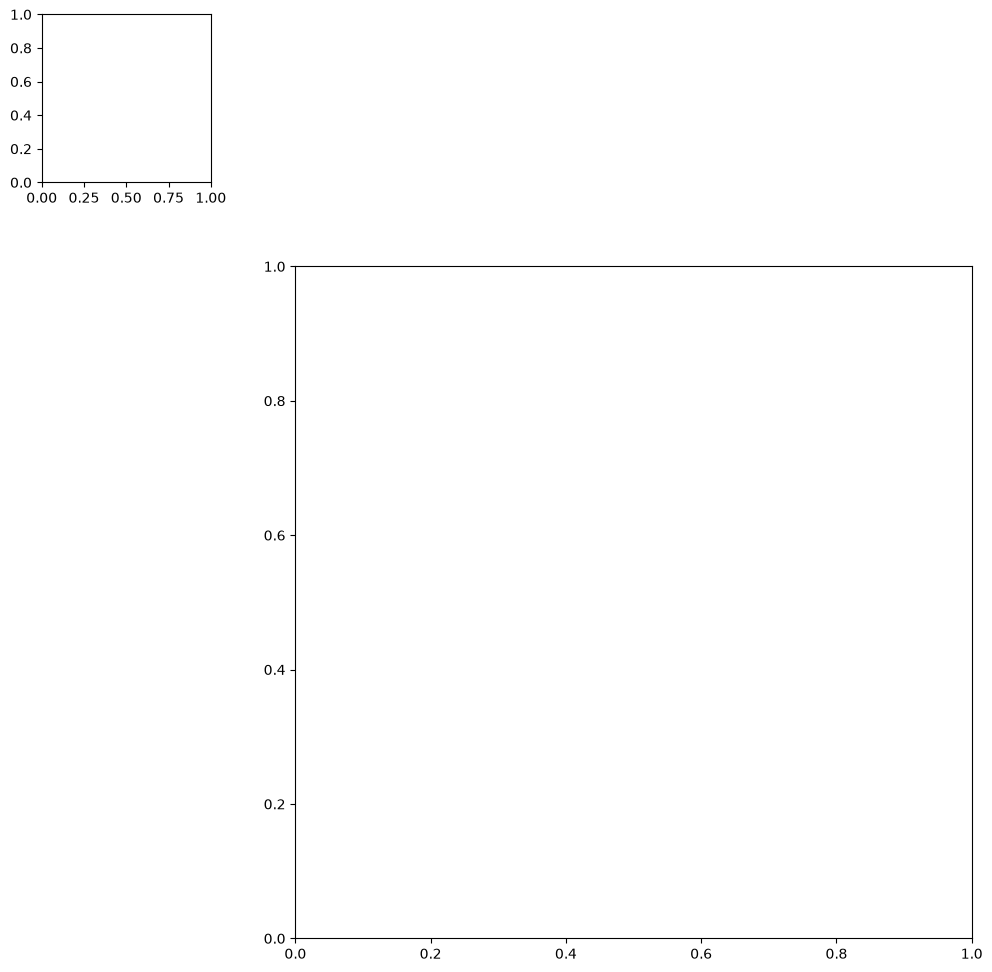

In [11]:
variable_genes = full_expression.var(axis=0) > 0
correlation_for_plot = full_gene_correlation.loc[variable_genes, variable_genes]
full_gene_linkage = linkage(
    squareform(np.clip(1 - correlation_for_plot.to_numpy(), 0, 2), checks=False),
    method="average",
)
full_clustermap = sns.clustermap(
    correlation_for_plot,
    row_linkage=full_gene_linkage,
    col_linkage=full_gene_linkage,
    cmap="vlag", center=0, vmin=-1, vmax=1,
    xticklabels=False, yticklabels=False, figsize=(12, 12),
    rasterized=True,
    cbar_kws={"label": "Pearson correlation"},
)
full_clustermap.fig.suptitle(f"TOME {stage}: full-gene correlation, 1,000 cells", y=1.02)
full_clustermap.savefig(output_dir / f"tome_{stage}_full_gene_correlation_clustermap_1000cells.png", dpi=150)
plt.show()